In [1]:
from pathlib import Path

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchvision.models import (
    convnext_base,
    ConvNeXt_Base_Weights
)

from tqdm.auto import tqdm

In [2]:
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/overgame1234/sid-set-processed-224")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Train:", TRAIN_DIR.exists())
print("Val:", VAL_DIR.exists())
print("Test:", TEST_DIR.exists())

Train: True
Val: True
Test: True


In [3]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
eval_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Classes:", train_dataset.classes)
print("Mapping:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['full_synthetic', 'real', 'tampered']
Mapping: {'full_synthetic': 0, 'real': 1, 'tampered': 2}
Train: 2783
Val: 596
Test: 597


In [6]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

In [7]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [8]:
import torch.nn as nn

from torchvision.models import (
    convnext_small,
    ConvNeXt_Small_Weights
)

weights = ConvNeXt_Small_Weights.IMAGENET1K_V1

model = convnext_small(
    weights=weights
)

model.classifier[2] = nn.Linear(
    model.classifier[2].in_features,
    3
)

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:01<00:00, 174MB/s] 


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=3, bias=True)
)


In [9]:
# Freeze كامل الموديل
for param in model.parameters():
    param.requires_grad = False

# افتح آخر stage
for param in model.features[-2:].parameters():
    param.requires_grad = True

# افتح classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [10]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 49,456,995
Trainable parameters: 15,474,435
Trainable percentage: 31.29%


In [11]:
criterion = nn.CrossEntropyLoss()

In [12]:
optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-3
)

In [13]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [14]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [15]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [16]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    desc="Validation"
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc=desc
        )

        for images, labels in progress:

            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [17]:
CHECKPOINT_DIR = Path(
    "/kaggle/working/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_val_loss = float("inf")
best_val_acc = 0.0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

In [18]:
EPOCHS = 15
PATIENCE = 4

for epoch in range(EPOCHS):

    print()
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print()
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2%}")

    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.2%}")

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    checkpoint = {
        "epoch": epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "classes":
            train_dataset.classes,

        "class_to_idx":
            train_dataset.class_to_idx
    }

    # checkpoint لكل epoch
    torch.save(
        checkpoint,
        CHECKPOINT_DIR
        / f"checkpoint_epoch_{epoch + 1}.pth"
    )

    print(
        f"Checkpoint saved: epoch {epoch + 1}"
    )

    # أفضل Val Loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            checkpoint,
            CHECKPOINT_DIR
            / "best_loss_model.pth"
        )

        print("Best loss model updated.")

    else:

        epochs_without_improvement += 1

    # أفضل Accuracy
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            checkpoint,
            CHECKPOINT_DIR
            / "best_accuracy_model.pth"
        )

        print("Best accuracy model updated.")

    print(
        f"No loss improvement: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    if epochs_without_improvement >= PATIENCE:

        print()
        print("Early stopping triggered.")
        break


Epoch 1/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 1.0468
Train Accuracy: 44.99%
Val Loss: 0.9250
Val Accuracy: 58.56%
Learning Rate: 1e-05
Checkpoint saved: epoch 1
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/4

Epoch 2/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 0.2726
Train Accuracy: 90.73%
Val Loss: 0.3412
Val Accuracy: 85.40%
Learning Rate: 1e-05
Checkpoint saved: epoch 14
Best loss model updated.
No loss improvement: 0/4

Epoch 15/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 0.2552
Train Accuracy: 91.92%
Val Loss: 0.3367
Val Accuracy: 85.07%
Learning Rate: 1e-05
Checkpoint saved: epoch 15
Best loss model updated.
No loss improvement: 0/4


In [20]:
import matplotlib.pyplot as plt
import numpy as np

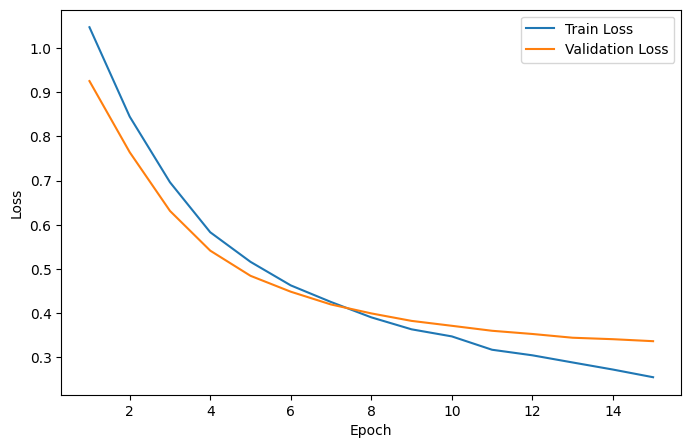

In [21]:
epochs_range = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

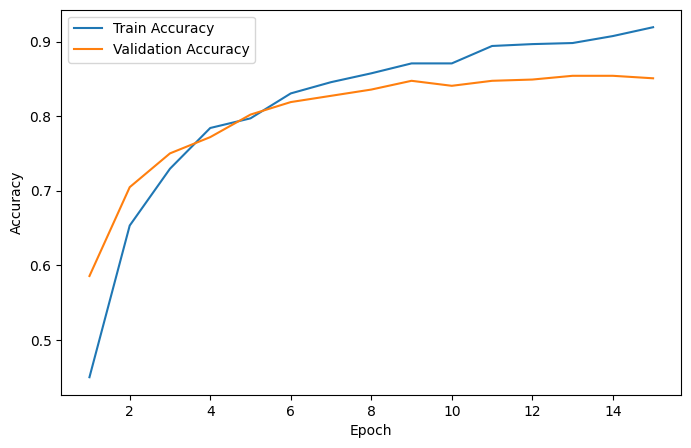

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

In [23]:
best_checkpoint = torch.load(
    CHECKPOINT_DIR
    / "best_accuracy_model.pth",
    map_location=device
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Validation Accuracy:",
    f"{best_checkpoint['val_acc']:.2%}"
)

print(
    "Validation Loss:",
    f"{best_checkpoint['val_loss']:.4f}"
)

Best epoch: 13
Validation Accuracy: 85.40%
Validation Loss: 0.3445


In [ ]:
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device,
    desc="Testing"
)

print()
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2%}")

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Final predictions"
    ):

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

all_labels = np.array(
    all_labels
)

all_predictions = np.array(
    all_predictions
)

In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=train_dataset.classes,
        digits=4
    )
)